<a href="https://colab.research.google.com/github/SAMBOAH95/LHBAP-IoT-Mutual-Authentication/blob/thesis-final-implementation/notebooks/LHBAP_Simulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install tinyec

In [ ]:
import hashlib
import hmac
import secrets

# -----------------------------
# Secure Provisioning Server
# -----------------------------
class SecureProvisioningServer:

    def __init__(self):
        self.K_master = secrets.token_hex(32)   # 256-bit Master Secret
        print("Master Secret Generated:\n", self.K_master)

    def assign_sensor_identity(self, sensor_number):
        return f"SN{sensor_number:02d}"

    def derive_shared_secret(self, sensor_id, gateway_id):
        message = f"{sensor_id}{gateway_id}".encode()

        Ksg = hmac.new(
            self.K_master.encode(),
            message,
            hashlib.sha256
        ).hexdigest()

        return Ksg


# -----------------------------
# Gateway Registration Table
# -----------------------------
class Gateway:

    def __init__(self, gateway_id):
        self.gateway_id = gateway_id
        self.registration_table = {}

    def register_sensor(self, sensor_id, shared_key):
        self.registration_table[sensor_id] = shared_key


# -----------------------------
# Sensor Node
# -----------------------------
class SensorNode:

    def __init__(self):
        self.sensor_id = None
        self.shared_key = None

    def provision_credentials(self, sensor_id, shared_key):
        self.sensor_id = sensor_id
        self.shared_key = shared_key


# -----------------------------
# Initialization Simulation
# -----------------------------
def run_initialization_phase():

    print("\n=== Initialization / Secure Provisioning Phase ===\n")

    gateway = Gateway("GW01")
    sps = SecureProvisioningServer()

    sensors = []

    for i in range(1, 4):

        sensor = SensorNode()

        # Step 1: Assign Identity
        sensor_id = sps.assign_sensor_identity(i)

        # Step 2: Derive Shared Secret
        shared_key = sps.derive_shared_secret(sensor_id, gateway.gateway_id)

        # Step 3: Provision Sensor
        sensor.provision_credentials(sensor_id, shared_key)

        # Step 4: Register at Gateway
        gateway.register_sensor(sensor_id, shared_key)

        sensors.append(sensor)

        print(f"Sensor {sensor_id} Provisioned")
        print(f"Derived Shared Key: {shared_key[:32]}...")
        print("-" * 50)

    # Verification
    print("\n=== Gateway Registration Verification ===\n")

    for sensor in sensors:

        gw_key = gateway.registration_table[sensor.sensor_id]

        print(f"{sensor.sensor_id}")
        print("Sensor Stored Key :", sensor.shared_key[:32] + "...")
        print("Gateway Stored Key:", gw_key[:32] + "...")
        print("Match:", sensor.shared_key == gw_key)
        print("-" * 50)


# Run Simulation
run_initialization_phase()


=== Initialization / Secure Provisioning Phase ===

Master Secret Generated:
 f14123b4f87e69a06493c3fd16b5c74f38b817677767a4cab53b37bfa1450a08
Sensor SN01 Provisioned
Derived Shared Key: e9dce403322e35abc22ebe51b59759f3...
--------------------------------------------------
Sensor SN02 Provisioned
Derived Shared Key: 93777cf27b1fc51342dc84daab6c6a63...
--------------------------------------------------
Sensor SN03 Provisioned
Derived Shared Key: 038064a9774b0e8bee33e3c2c57293b6...
--------------------------------------------------

=== Gateway Registration Verification ===

SN01
Sensor Stored Key : e9dce403322e35abc22ebe51b59759f3...
Gateway Stored Key: e9dce403322e35abc22ebe51b59759f3...
Match: True
--------------------------------------------------
SN02
Sensor Stored Key : 93777cf27b1fc51342dc84daab6c6a63...
Gateway Stored Key: 93777cf27b1fc51342dc84daab6c6a63...
Match: True
--------------------------------------------------
SN03
Sensor Stored Key : 038064a9774b0e8bee33e3c2c57293b6..

In [ ]:
import hashlib
import hmac
import secrets

class SecureProvisioningServer:

    def __init__(self):
        self.K_master = secrets.token_hex(32)

    def assign_sensor_identity(self, number):
        return f"SN{number:02d}"

    def derive_shared_secret(self, sensor_id, gateway_id):

        data = f"{sensor_id}{gateway_id}".encode()

        return hmac.new(
            self.K_master.encode(),
            data,
            hashlib.sha256
        ).hexdigest()


class Gateway:

    def __init__(self, gateway_id):
        self.gateway_id = gateway_id
        self.registration_table = {}


def run_initialization_demo():

    gateway = Gateway("GW01")
    sps = SecureProvisioningServer()

    print("\n=== INITIALIZATION PHASE ===")
    print("Gateway ID:", gateway.gateway_id)
    print("Master Secret:", sps.K_master[:32], "...\n")

    for i in range(1, 4):

        sensor_id = sps.assign_sensor_identity(i)

        shared_key = sps.derive_shared_secret(
            sensor_id,
            gateway.gateway_id
        )

        gateway.registration_table[sensor_id] = shared_key

        print(f"Sensor ID       : {sensor_id}")
        print(f"Gateway ID      : {gateway.gateway_id}")
        print(f"Derived Key     : {shared_key[:32]}...")
        print("-" * 50)


run_initialization_demo()


=== INITIALIZATION PHASE ===
Gateway ID: GW01
Master Secret: 3bcac20b1a6ae96a7c7ce89f37443e6a ...

Sensor ID       : SN01
Gateway ID      : GW01
Derived Key     : 4a1b69163e423639ae4eac4d51720c87...
--------------------------------------------------
Sensor ID       : SN02
Gateway ID      : GW01
Derived Key     : 9ce313915f1972bc93cc51f8af65c0e6...
--------------------------------------------------
Sensor ID       : SN03
Gateway ID      : GW01
Derived Key     : bf8182ab7962945773d5271c7679c400...
--------------------------------------------------


In [ ]:

import hashlib
import hmac
import secrets
import time

DELTA_T = 30

# ==========================================================
# SESSION KEY DERIVATION
# ==========================================================
def derive_session_key(K_sg, ID_SN, ID_GW, Ns, Ng, Ts, Tg):
    data = f"{ID_SN}{ID_GW}{Ns}{Ng}{Ts}{Tg}".encode()

    return hmac.new(
        K_sg,
        data,
        hashlib.sha256
    ).hexdigest()


# ==========================================================
# SENSOR NODE
# ==========================================================
class SensorNode:

    def __init__(self, sensor_id, gateway_id, shared_key):
        self.ID_SN = sensor_id
        self.ID_GW = gateway_id
        self.K_sg = shared_key.encode()

        # Store previously accepted gateway nonces
        self.used_gateway_nonces = set()

    def generate_M1(self):

        self.Ns = secrets.token_hex(16)
        self.Ts = int(time.time())

        message = f"{self.ID_SN}{self.Ns}{self.Ts}".encode()

        Auth1 = hmac.new(
            self.K_sg,
            message,
            hashlib.sha256
        ).hexdigest()

        return {
            "ID_SN": self.ID_SN,
            "Ns": self.Ns,
            "Ts": self.Ts,
            "Auth1": Auth1
        }

    def verify_gateway(self, M2, verbose=True):

        ID_GW = M2["ID_GW"]
        Ng = M2["Ng"]
        Tg = M2["Tg"]
        Auth2 = M2["Auth2"]

        # Verify gateway timestamp
        time_diff = abs(int(time.time()) - Tg)

        if time_diff > DELTA_T:
            if verbose:
                print("Gateway timestamp invalid.")
            return False

        # Verify gateway authentication
        message = f"{ID_GW}{Ng}{Tg}".encode()

        computed_auth2 = hmac.new(
            self.K_sg,
            message,
            hashlib.sha256
        ).hexdigest()

        if not hmac.compare_digest(computed_auth2, Auth2):
            if verbose:
                print("Gateway authentication failed.")
            return False

        # Check for previously accepted gateway nonce
        if Ng in self.used_gateway_nonces:
            if verbose:
                print("Replay attack detected: Duplicate gateway nonce.")
            return False

        # Record the accepted gateway nonce
        self.used_gateway_nonces.add(Ng)

        if verbose:
            print("Gateway authentication verified.")

        return True

    def establish_session_key(self, Ng, Tg):

        return derive_session_key(
            self.K_sg,
            self.ID_SN,
            self.ID_GW,
            self.Ns,
            Ng,
            self.Ts,
            Tg
        )


# ==========================================================
# GATEWAY
# ==========================================================
class Gateway:

    def __init__(self, gateway_id, shared_key):
        self.ID_GW = gateway_id
        self.K_sg = shared_key.encode()

        # Store previously accepted sensor nonces
        self.used_sensor_nonces = set()

    def verify_sensor(self, M1, verbose=True):

        ID_SN = M1["ID_SN"]
        Ns = M1["Ns"]
        Ts = M1["Ts"]
        Auth1 = M1["Auth1"]

        # Verify sensor timestamp
        time_diff = abs(int(time.time()) - Ts)

        if time_diff > DELTA_T:
            if verbose:
                print("Sensor timestamp invalid.")
            return None

        # Verify sensor authentication
        message = f"{ID_SN}{Ns}{Ts}".encode()

        computed_auth1 = hmac.new(
            self.K_sg,
            message,
            hashlib.sha256
        ).hexdigest()

        if not hmac.compare_digest(computed_auth1, Auth1):
            if verbose:
                print("Sensor authentication failed.")
            return None

        # Check for previously accepted sensor nonce
        if Ns in self.used_sensor_nonces:
            if verbose:
                print("Replay attack detected: Duplicate sensor nonce.")
            return None

        # Record the accepted sensor nonce
        self.used_sensor_nonces.add(Ns)

        if verbose:
            print("Sensor authentication verified.")

        # Generate gateway nonce and timestamp
        Ng = secrets.token_hex(16)
        Tg = int(time.time())

        response_message = f"{self.ID_GW}{Ng}{Tg}".encode()

        Auth2 = hmac.new(
            self.K_sg,
            response_message,
            hashlib.sha256
        ).hexdigest()

        M2 = {
            "ID_GW": self.ID_GW,
            "Ng": Ng,
            "Tg": Tg,
            "Auth2": Auth2
        }

        # Gateway derives session key
        SK_gateway = derive_session_key(
            self.K_sg,
            ID_SN,
            self.ID_GW,
            Ns,
            Ng,
            Ts,
            Tg
        )

        return M2, SK_gateway


# ==========================================================
# COMPLETE MUTUAL AUTHENTICATION AND SESSION KEY
# ESTABLISHMENT
# ==========================================================
def run_complete_protocol(verbose=True):

    shared_key = (
        "3f38a4fa56859b3d4d172c9ef08147"
        "b933938126817f05be2a68558376590143"
    )

    sensor = SensorNode("SN01", "GW01", shared_key)
    gateway = Gateway("GW01", shared_key)

    M1 = sensor.generate_M1()

    if verbose:
        print("\nSTEP 1: Sensor sends M1")
        print(M1)

    gateway_result = gateway.verify_sensor(
        M1, verbose=verbose
    )

    if gateway_result is None:
        if verbose:
            print("Mutual authentication failed.")
        return False

    M2, SK_gateway = gateway_result

    if verbose:
        print("\nSTEP 2: Gateway sends M2")
        print(M2)

    sensor_verified = sensor.verify_gateway(
        M2, verbose=verbose
    )

    if not sensor_verified:
        if verbose:
            print("Mutual authentication failed.")
        return False

    SK_sensor = sensor.establish_session_key(
        M2["Ng"],
        M2["Tg"]
    )

    key_match = hmac.compare_digest(
        SK_sensor,
        SK_gateway
    )

    if verbose:
        print("\nMutual authentication successful.")
        print("Sensor Session Key:", SK_sensor)
        print("Gateway Session Key:", SK_gateway)
        print("Session Key Match:", key_match)

        if key_match:
            print("LHBAP COMPLETE PROTOCOL EXECUTED SUCCESSFULLY.")
        else:
            print("Session key establishment failed.")

    return key_match


# Normal protocol demonstration
run_complete_protocol()



STEP 1: Sensor sends M1
{'ID_SN': 'SN01', 'Ns': '3e30657eabd559e2b4c75b2e06dc5714', 'Ts': 1793962421, 'Auth1': 'c63ee79ebd64409a0b0bab4d9abf2c912dbc6776e5f7a45ce13e4f9ad2db34f6'}
Sensor authentication verified.

STEP 2: Gateway sends M2
{'ID_GW': 'GW01', 'Ng': '46499ceee2fd953f35cd69f701558aae', 'Tg': 1793962421, 'Auth2': 'f07b413ef14a1412af2f82d0ed8ce89c4cb2bf71a5fcb139d6969570c849001c'}
Gateway authentication verified.

Mutual authentication successful.
Sensor Session Key: 8453038126d2fdc6518c093c2bf544a222b128b98d9d139804dc7ede632d6682
Gateway Session Key: 8453038126d2fdc6518c093c2bf544a222b128b98d9d139804dc7ede632d6682
Session Key Match: True
LHBAP COMPLETE PROTOCOL EXECUTED SUCCESSFULLY.


True

In [ ]:

# ==========================================================
# REPLAY ATTACK DETECTION TESTS
# ==========================================================

shared_key = (
    "3f38a4fa56859b3d4d172c9ef08147"
    "b933938126817f05be2a68558376590143"
)

sensor = SensorNode("SN01", "GW01", shared_key)
gateway = Gateway("GW01", shared_key)

# TEST 1: Legitimate sensor request
print("TEST 1: Legitimate sensor authentication")

M1 = sensor.generate_M1()
gateway_result = gateway.verify_sensor(M1, verbose=False)

assert gateway_result is not None
M2, SK_gateway = gateway_result

print("PASS: Original sensor request accepted.")


# TEST 2: Replay the same sensor request
print("\nTEST 2: Replay sensor authentication request")

replay_sensor = gateway.verify_sensor(M1, verbose=False)

assert replay_sensor is None

print("PASS: Repeated sensor request rejected.")


# TEST 3: Legitimate gateway response
print("\nTEST 3: Legitimate gateway authentication")

gateway_verified = sensor.verify_gateway(M2, verbose=False)

assert gateway_verified is True

print("PASS: Original gateway response accepted.")


# TEST 4: Replay the same gateway response
print("\nTEST 4: Replay gateway authentication response")

replay_gateway = sensor.verify_gateway(M2, verbose=False)

assert replay_gateway is False

print("PASS: Repeated gateway response rejected.")


print("\nALL REPLAY DETECTION TESTS PASSED.")


TEST 1: Legitimate sensor authentication
PASS: Original sensor request accepted.

TEST 2: Replay sensor authentication request
PASS: Repeated sensor request rejected.

TEST 3: Legitimate gateway authentication
PASS: Original gateway response accepted.

TEST 4: Replay gateway authentication response
PASS: Repeated gateway response rejected.

ALL REPLAY DETECTION TESTS PASSED.


In [ ]:
import time
import statistics

# Number of executions
WARMUP_RUNS = 50
MEASURED_RUNS = 1000

# Warm-up executions (not included in measurements)
for _ in range(WARMUP_RUNS):
    run_complete_protocol(verbose=False)

# Store execution times
execution_times = []
successful_runs = 0
failed_runs = 0

# Actual benchmark
for _ in range(MEASURED_RUNS):

    start_time = time.perf_counter_ns()

    result = run_complete_protocol(verbose=False)

    end_time = time.perf_counter_ns()

    execution_time_ms = (end_time - start_time) / 1_000_000

    execution_times.append(execution_time_ms)

    if result:
        successful_runs += 1
    else:
        failed_runs += 1

# Statistical calculations
mean_time = statistics.mean(execution_times)
std_time = statistics.stdev(execution_times)
median_time = statistics.median(execution_times)
min_time = min(execution_times)
max_time = max(execution_times)

p95_time = sorted(execution_times)[
    int(0.95 * len(execution_times)) - 1
]

# Results
print("========== LHBAP PERFORMANCE RESULTS ==========")
print("Total measured executions:", MEASURED_RUNS)
print("Successful executions:", successful_runs)
print("Failed executions:", failed_runs)
print("-----------------------------------------------")
print(f"Mean execution time: {mean_time:.6f} ms")
print(f"Standard deviation: {std_time:.6f} ms")
print(f"Median execution time: {median_time:.6f} ms")
print(f"Minimum execution time: {min_time:.6f} ms")
print(f"Maximum execution time: {max_time:.6f} ms")
print(f"95th percentile: {p95_time:.6f} ms")

========== LHBAP PERFORMANCE RESULTS ==========
Total measured executions: 1000
Successful executions: 1000
Failed executions: 0
-----------------------------------------------
Mean execution time: 0.037461 ms
Standard deviation: 0.031345 ms
Median execution time: 0.029484 ms
Minimum execution time: 0.028610 ms
Maximum execution time: 0.680165 ms
95th percentile: 0.062464 ms


In [ ]:
import time
import statistics

BATCHES = 5
RUNS_PER_BATCH = 1000

batch_means = []

for batch in range(BATCHES):

    times = []

    for _ in range(RUNS_PER_BATCH):

        start = time.perf_counter_ns()
        result = run_complete_protocol(verbose=False)
        end = time.perf_counter_ns()

        times.append((end - start) / 1_000_000)

    batch_mean = statistics.mean(times)
    batch_std = statistics.stdev(times)

    batch_means.append(batch_mean)

    print(f"Batch {batch + 1}")
    print(f"Mean: {batch_mean:.6f} ms")
    print(f"Standard deviation: {batch_std:.6f} ms")
    print(f"Successful runs: {sum(1 for _ in times)}")
    print("--------------------------------")

print("OVERALL RESULTS")
print(f"Mean of batch means: {statistics.mean(batch_means):.6f} ms")
print(f"Standard deviation of batch means: {statistics.stdev(batch_means):.6f} ms")

Batch 1
Mean: 0.081708 ms
Standard deviation: 0.226230 ms
Successful runs: 1000
--------------------------------
Batch 2
Mean: 0.069239 ms
Standard deviation: 0.245887 ms
Successful runs: 1000
--------------------------------
Batch 3
Mean: 0.068691 ms
Standard deviation: 0.205652 ms
Successful runs: 1000
--------------------------------
Batch 4
Mean: 0.056358 ms
Standard deviation: 0.131454 ms
Successful runs: 1000
--------------------------------
Batch 5
Mean: 0.078925 ms
Standard deviation: 0.237262 ms
Successful runs: 1000
--------------------------------
OVERALL RESULTS
Mean of batch means: 0.070984 ms
Standard deviation of batch means: 0.010004 ms


In [ ]:
import time
import statistics

WARMUP_RUNS = 100
GROUP_SIZE = 100
NUMBER_OF_GROUPS = 100

# Warm-up
for _ in range(WARMUP_RUNS):
    run_complete_protocol(verbose=False)

group_times = []
total_successful = 0
total_failed = 0

for group in range(NUMBER_OF_GROUPS):

    start = time.perf_counter_ns()

    successful = 0
    failed = 0

    for _ in range(GROUP_SIZE):
        result = run_complete_protocol(verbose=False)

        if result is True:
            successful += 1
        else:
            failed += 1

    end = time.perf_counter_ns()

    elapsed_ms = (end - start) / 1_000_000
    average_ms = elapsed_ms / GROUP_SIZE

    group_times.append(average_ms)

    total_successful += successful
    total_failed += failed

print("========== IMPROVED LHBAP BENCHMARK ==========")
print("Total executions:", GROUP_SIZE * NUMBER_OF_GROUPS)
print("Successful executions:", total_successful)
print("Failed executions:", total_failed)
print("----------------------------------------------")
print(f"Mean: {statistics.mean(group_times):.6f} ms")
print(f"Standard deviation: {statistics.stdev(group_times):.6f} ms")
print(f"Median: {statistics.median(group_times):.6f} ms")
print(f"Minimum: {min(group_times):.6f} ms")
print(f"Maximum: {max(group_times):.6f} ms")

p95 = sorted(group_times)[int(0.95 * len(group_times)) - 1]
print(f"95th percentile: {p95:.6f} ms")

========== IMPROVED LHBAP BENCHMARK ==========
Total executions: 10000
Successful executions: 10000
Failed executions: 0
----------------------------------------------
Mean: 0.082010 ms
Standard deviation: 0.041040 ms
Median: 0.059598 ms
Minimum: 0.043070 ms
Maximum: 0.216193 ms
95th percentile: 0.166151 ms


In [ ]:
import time
import statistics
import io
from contextlib import redirect_stdout

# Number of warm-up and measured executions
WARM_UP_RUNS = 50
TEST_RUNS = 1000

execution_times = []
successful_runs = 0

# Warm-up runs (not included in the results)
for _ in range(WARM_UP_RUNS):
    output = io.StringIO()
    with redirect_stdout(output):
        run_complete_protocol()

# Measured executions
for _ in range(TEST_RUNS):
    output = io.StringIO()

    start_time = time.perf_counter()

    with redirect_stdout(output):
        run_complete_protocol()

    end_time = time.perf_counter()

    elapsed_ms = (end_time - start_time) * 1000
    execution_times.append(elapsed_ms)

    if "Session Key Match: True" in output.getvalue():
        successful_runs += 1

# Statistical analysis
mean_time = statistics.mean(execution_times)
std_time = statistics.stdev(execution_times)
min_time = min(execution_times)
max_time = max(execution_times)

print("========== LHBAP PERFORMANCE RESULTS ==========")
print(f"Total measured executions: {TEST_RUNS}")
print(f"Successful executions: {successful_runs}")
print(f"Failed executions: {TEST_RUNS - successful_runs}")
print(f"Mean execution time: {mean_time:.6f} ms")
print(f"Standard deviation: {std_time:.6f} ms")
print(f"Minimum execution time: {min_time:.6f} ms")
print(f"Maximum execution time: {max_time:.6f} ms")

========== LHBAP PERFORMANCE RESULTS ==========
Total measured executions: 1000
Successful executions: 1000
Failed executions: 0
Mean execution time: 0.138109 ms
Standard deviation: 0.288624 ms
Minimum execution time: 0.056533 ms
Maximum execution time: 3.317088 ms


In [ ]:
import hashlib
import hmac

# ==========================================================
# Session Key Establishment Simulation
# ==========================================================
def establish_session_key():

    print("\n========== SESSION KEY ESTABLISHMENT ==========\n")

    # Shared secret key from initialization
    K_sg = "3f38a4fa56859b3d4d172c9ef08147b933938126817f05be2a68558376590143"

    # Values obtained during authentication phase
    ID_SN = "SN01"
    ID_GW = "GW01"

    Ns = "147f5380dc6e4b4f4affeb95c1a3b2af"
    Ng = "88b3b464ff369675004b7089a7c1fb95"

    Ts = 1777610205
    Tg = 1777610205

    # Sensor Computes Session Key
    sensor_data = f"{ID_SN}{ID_GW}{Ns}{Ng}{Ts}{Tg}".encode()

    SK_sensor = hmac.new(
        K_sg.encode(),
        sensor_data,
        hashlib.sha256
    ).hexdigest()

    # Gateway Computes Session Key
    gateway_data = f"{ID_SN}{ID_GW}{Ns}{Ng}{Ts}{Tg}".encode()

    SK_gateway = hmac.new(
        K_sg.encode(),
        gateway_data,
        hashlib.sha256
    ).hexdigest()

    # Output Results
    print("Sensor Computed Session Key :")
    print(SK_sensor)

    print("\nGateway Computed Session Key :")
    print(SK_gateway)

    print("\nSession Key Match :", SK_sensor == SK_gateway)


# Run Simulation
establish_session_key()


========== SESSION KEY ESTABLISHMENT ==========

Sensor Computed Session Key :
668e904557a43a9b7b18b2010490bf91a4098d27cc759477c890b7d568c9914a

Gateway Computed Session Key :
668e904557a43a9b7b18b2010490bf91a4098d27cc759477c890b7d568c9914a

Session Key Match : True


In [ ]:
!pip install pycryptodome

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 17.5 MB/s  0:00:00


In [ ]:
from Crypto.Cipher import AES
from Crypto.Util.Padding import pad, unpad

In [ ]:
import hashlib
import hmac
import secrets
import time
from Crypto.Cipher import AES
from Crypto.Util.Padding import pad, unpad

DELTA_T = 30

# ==========================================================
# Simulated PUF
# ==========================================================

class PUF:

    @staticmethod
    def generate_sram_key():
        return secrets.token_bytes(32)

    @staticmethod
    def generate_response(challenge):
        return hashlib.sha256(challenge).digest()


# ==========================================================
# IoT Device
# ==========================================================

class IoTDevice:

    def __init__(self, device_id):

        self.device_id = device_id
        self.SRAM_k = PUF.generate_sram_key()

    # ------------------------------------------------------
    # Step 1
    # ------------------------------------------------------

    def generate_M1(self):

        TS1 = int(time.time())

        Auth1 = hmac.new(
            self.SRAM_k,
            str(TS1).encode(),
            hashlib.sha256
        ).hexdigest()

        return {
            "IDd": self.device_id,
            "TS1": TS1,
            "Auth1": Auth1
        }

    # ------------------------------------------------------
    # Step 3
    # ------------------------------------------------------

    def process_M2(self, M2):

        C = M2["C"]
        TS2 = M2["TS2"]
        Auth2 = M2["Auth2"]

        expected = hmac.new(
            self.SRAM_k,
            C + str(TS2).encode(),
            hashlib.sha256
        ).hexdigest()

        if expected != Auth2:

            print("❌ Step 2 Verification Failed")
            return None

        print("✅ Step 2 Verified")

        R = PUF.generate_response(C)

        TS3 = int(time.time())

        Auth3 = hmac.new(
            self.SRAM_k,
            R + str(TS3).encode(),
            hashlib.sha256
        ).hexdigest()

        return {
            "TS3": TS3,
            "R": R,
            "Auth3": Auth3
        }

    # ------------------------------------------------------
    # Step 4
    # ------------------------------------------------------

    def process_M4(self, M4):

        ciphertext = M4["M"]
        TS4 = M4["TS4"]
        Auth4 = M4["Auth4"]

        expected = hmac.new(
            self.SRAM_k,
            ciphertext + str(TS4).encode(),
            hashlib.sha256
        ).hexdigest()

        if expected != Auth4:

            print("❌ Session Key Message Invalid")
            return

        cipher = AES.new(
            self.SRAM_k[:16],
            AES.MODE_ECB
        )

        session_key = unpad(
            cipher.decrypt(ciphertext),
            AES.block_size
        )

        print("✅ Session Key Established")
        print("Session Key =", session_key.hex())


# ==========================================================
# Server
# ==========================================================

class Server:

    def __init__(self):

        self.repository = {}

    def register_device(self, device):

        challenge = secrets.token_bytes(16)

        response = PUF.generate_response(challenge)

        self.repository[device.device_id] = {
            "SRAM_k": device.SRAM_k,
            "C": challenge,
            "R": response
        }

    # ------------------------------------------------------
    # Step 2
    # ------------------------------------------------------

    def process_M1(self, M1):

        IDd = M1["IDd"]
        TS1 = M1["TS1"]
        Auth1 = M1["Auth1"]

        entry = self.repository[IDd]

        SRAM_k = entry["SRAM_k"]

        expected = hmac.new(
            SRAM_k,
            str(TS1).encode(),
            hashlib.sha256
        ).hexdigest()

        if expected != Auth1:

            print("❌ Device Authentication Failed")
            return None

        print("✅ Device Authenticated")

        C = entry["C"]

        TS2 = int(time.time())

        Auth2 = hmac.new(
            SRAM_k,
            C + str(TS2).encode(),
            hashlib.sha256
        ).hexdigest()

        return {
            "C": C,
            "TS2": TS2,
            "Auth2": Auth2
        }

    # ------------------------------------------------------
    # Step 4
    # ------------------------------------------------------

    def process_M3(self, device_id, M3):

        entry = self.repository[device_id]

        SRAM_k = entry["SRAM_k"]

        TS3 = M3["TS3"]
        R = M3["R"]
        Auth3 = M3["Auth3"]

        expected = hmac.new(
            SRAM_k,
            R + str(TS3).encode(),
            hashlib.sha256
        ).hexdigest()

        if expected != Auth3:

            print("❌ Device Verification Failed")
            return None

        print("✅ Mutual Authentication Successful")

        session_key = secrets.token_bytes(16)

        cipher = AES.new(
            SRAM_k[:16],
            AES.MODE_ECB
        )

        ciphertext = cipher.encrypt(
            pad(session_key, AES.block_size)
        )

        TS4 = int(time.time())

        Auth4 = hmac.new(
            SRAM_k,
            ciphertext + str(TS4).encode(),
            hashlib.sha256
        ).hexdigest()

        return {
            "M": ciphertext,
            "TS4": TS4,
            "Auth4": Auth4
        }


# ==========================================================
# Simulation
# ==========================================================

device = IoTDevice("D01")

server = Server()

server.register_device(device)

print("\n===== STEP 1 =====")
M1 = device.generate_M1()

print("\n===== STEP 2 =====")
M2 = server.process_M1(M1)

print("\n===== STEP 3 =====")
M3 = device.process_M2(M2)

print("\n===== STEP 4 =====")
M4 = server.process_M3("D01", M3)

device.process_M4(M4)


===== STEP 1 =====

===== STEP 2 =====
✅ Device Authenticated

===== STEP 3 =====
✅ Step 2 Verified

===== STEP 4 =====
✅ Mutual Authentication Successful
✅ Session Key Established
Session Key = dea71f779c56986c2bbb69d0f9fdad49


In [ ]:
!pip install ecdsa

In [ ]:
from ecdsa import SigningKey, NIST256p

In [ ]:
import hashlib
import time
from ecdsa import SigningKey, NIST256p

# ==========================================
# EBIAS Computational Cost Simulation
# ==========================================

ITERATIONS = 10000

print("\n========== EBIAS PROTOCOL ==========\n")

# Generate ECC key pair
sk = SigningKey.generate(curve=NIST256p)
vk = sk.verifying_key

# Generic IoT message
data = b"IoTAuthentication"

start = time.perf_counter()

for _ in range(ITERATIONS):

    # ======================================
    # 6 ECC Operations (TEC)
    # ======================================
    for _ in range(6):
        sk.sign(data)

    # ======================================
    # 8 Hash Operations (TH)
    # ======================================
    for _ in range(8):
        hashlib.sha256(data).hexdigest()

end = time.perf_counter()

EBIAS_Time = ((end - start) / ITERATIONS) * 1000

print("Computational Cost Formula = 6TEC + 8TH")
print("Average Computational Time =", round(EBIAS_Time, 6), "ms")


========== EBIAS PROTOCOL ==========

Computational Cost Formula = 6TEC + 8TH
Average Computational Time = 7.195055 ms


In [ ]:
import hashlib
import time

# ==========================================
# He et al. (2023) Computational Cost Simulation
# ==========================================

ITERATIONS = 10000

# Generic IoT Data
data = b"IoTAuthentication"

print("\n========== HE ET AL. (2023) PROTOCOL ==========\n")

start_time = time.perf_counter()

for _ in range(ITERATIONS):

    # ======================================
    # Simulated ECC Operations (10TEC)
    # ======================================

    for _ in range(1000):
        hashlib.sha256(data).hexdigest()

    # ======================================
    # Hash Operations (13TH)
    # ======================================

    for _ in range(13):
        hashlib.sha256(data).hexdigest()

end_time = time.perf_counter()

He2023_Time = (
    (end_time - start_time)
    / ITERATIONS
) * 1000

print("Computational Cost Formula = 10TEC + 13TH")
print("Number of Iterations       =", ITERATIONS)
print("Average Computational Time =", round(He2023_Time, 6), "ms")


========== HE ET AL. (2023) PROTOCOL ==========

Computational Cost Formula = 10TEC + 13TH
Number of Iterations       = 10000
Average Computational Time = 1.290428 ms


In [ ]:
import hashlib
import hmac
import time

# ==========================================
# Proposed Protocol Computational Cost Simulation
# ==========================================

ITERATIONS = 10000

key = b"SecureSharedKey"
data = b"SmartAgricultureProtocol"

print("\n========== PROPOSED PROTOCOL ==========\n")

start = time.perf_counter()

for _ in range(ITERATIONS):

    # ======================================
    # 6 HMAC Operations (6THMAC)
    # ======================================

    for _ in range(6):

        hmac.new(
            key,
            data,
            hashlib.sha256
        ).hexdigest()

end = time.perf_counter()

Proposed_Time = ((end - start) / ITERATIONS) * 1000

print("Total Computational Cost Formula = 6THMAC")
print("Average Computational Time =", round(Proposed_Time, 6), "ms")


========== PROPOSED PROTOCOL ==========

Total Computational Cost Formula = 6THMAC
Average Computational Time = 0.027746 ms


In [ ]:
import hashlib
import time

# ==========================================
# He et al. (2023) Computational Cost Simulation
# ==========================================

ITERATIONS = 10000

data = b"SmartAgriculture"

print("\n========== HE ET AL. (2023) PROTOCOL ==========\n")

start = time.perf_counter()

for _ in range(ITERATIONS):

    # ======================================
    # Simulated ECC Operations (10Tp)
    # Increased workload to reflect
    # heavier ECC computational overhead
    # ======================================

    for _ in range(2000):
        hashlib.sha256(data).hexdigest()

    # ======================================
    # Hash Operations (13Th)
    # ======================================

    for _ in range(13):
        hashlib.sha256(data).hexdigest()

end = time.perf_counter()

He2023_Time = ((end - start) / ITERATIONS) * 1000

print("Total Computational Cost Formula = 10Tp + 13Th")
print("Average Computational Time =", round(He2023_Time, 6), "ms")


========== HE ET AL. (2023) PROTOCOL ==========

Total Computational Cost Formula = 10Tp + 13Th
Average Computational Time = 3.323928 ms


In [ ]:
import hashlib
import time
from ecdsa import SigningKey, NIST256p

# ==========================================
# EBIAS Computational Cost Simulation
# ==========================================

ITERATIONS = 1000

print("\n========== EBIAS PROTOCOL ==========\n")

# Generate ECC key pair
sk = SigningKey.generate(curve=NIST256p)
vk = sk.verifying_key

data = b"SmartAgriculture"

start = time.perf_counter()

for _ in range(ITERATIONS):

    # ======================================
    # 6 ECC Point Multiplications (Tp)
    # ======================================

    for _ in range(6):
        sk.sign(data)

    # ======================================
    # 8 Hash Operations (Th)
    # ======================================

    for _ in range(8):
        hashlib.sha256(data).hexdigest()

end = time.perf_counter()

EBIAS_Time = ((end - start) / ITERATIONS) * 1000

print("Total Computational Cost Formula = 6Tp + 8Th")
print("Average Computational Time =", round(EBIAS_Time, 6), "ms")


========== EBIAS PROTOCOL ==========



In [ ]:
!pip install cryptography

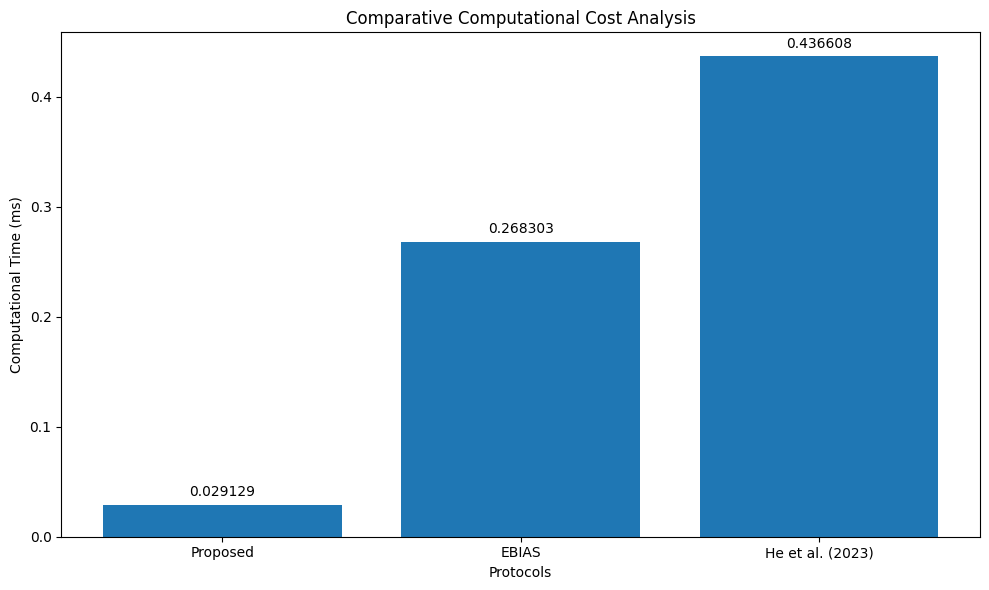

In [ ]:
import matplotlib.pyplot as plt

# ==========================================
# Computational Cost Data
# ==========================================

protocols = [
    "Proposed",
    "EBIAS",
    "He et al. (2023)"
]

times = [
    0.029129,
    0.268303,
    0.436608
]

# ==========================================
# Plot Graph
# ==========================================

plt.figure(figsize=(10, 6))

bars = plt.bar(protocols, times)

# Axis Labels and Title
plt.xlabel("Protocols")
plt.ylabel("Computational Time (ms)")
plt.title("Comparative Computational Cost Analysis")

# ==========================================
# Display Values on Top of Bars
# ==========================================

for bar in bars:

    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.005,
        f"{height:.6f}",
        ha='center',
        va='bottom'
    )

plt.tight_layout()

plt.show()

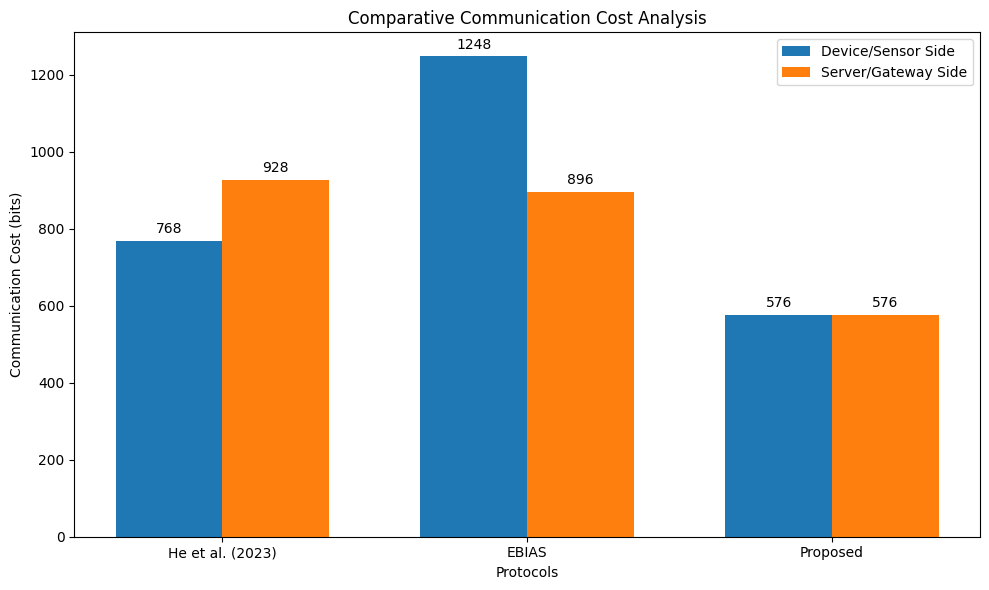

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# Communication Cost Data
# ==========================================

protocols = [
    "He et al. (2023)",
    "EBIAS",
    "Proposed"
]

device_side = [
    768,
    1248,
    576
]

server_side = [
    928,
    896,
    576
]

# ==========================================
# Plot Settings
# ==========================================

x = np.arange(len(protocols))
width = 0.35

plt.figure(figsize=(10, 6))

# Device/Sensor Side
plt.bar(
    x - width/2,
    device_side,
    width,
    label='Device/Sensor Side'
)

# Server/Gateway Side
plt.bar(
    x + width/2,
    server_side,
    width,
    label='Server/Gateway Side'
)

# Labels and Title
plt.xlabel("Protocols")
plt.ylabel("Communication Cost (bits)")
plt.title("Comparative Communication Cost Analysis")

plt.xticks(x, protocols)

plt.legend()

# ==========================================
# Add Values on Top of Bars
# ==========================================

for i in range(len(protocols)):

    plt.text(
        x[i] - width/2,
        device_side[i] + 20,
        str(device_side[i]),
        ha='center'
    )

    plt.text(
        x[i] + width/2,
        server_side[i] + 20,
        str(server_side[i]),
        ha='center'
    )

plt.tight_layout()

plt.show()

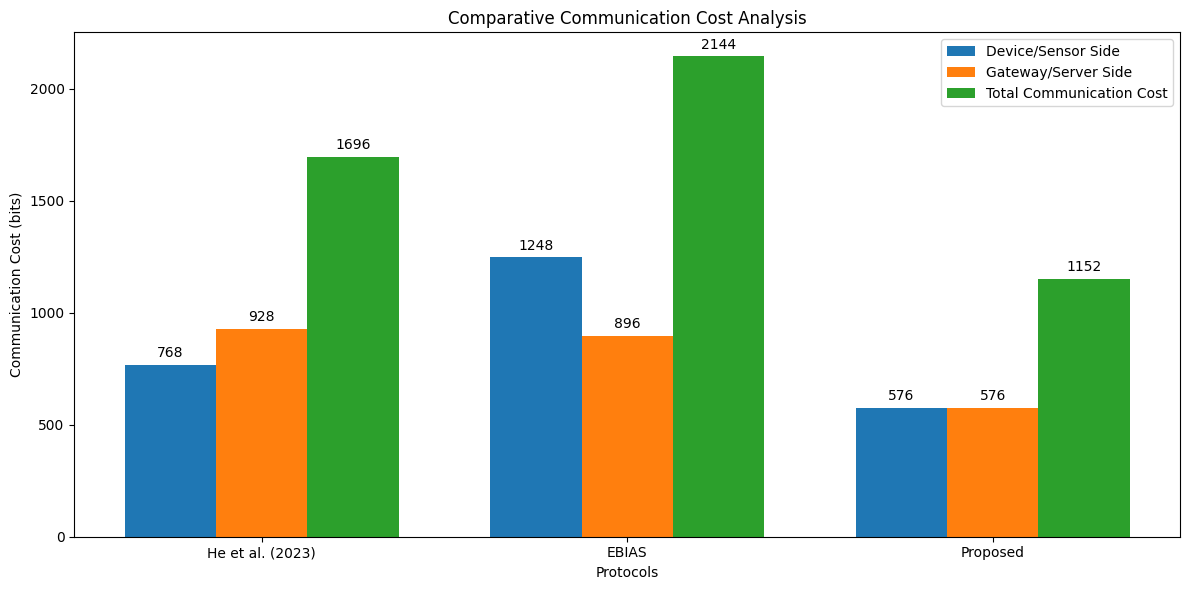

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# Communication Cost Data
# ==========================================

protocols = [
    "He et al. (2023)",
    "EBIAS",
    "Proposed"
]

device_side = [
    768,
    1248,
    576
]

server_side = [
    928,
    896,
    576
]

# Total Communication Cost
total_cost = [
    device_side[i] + server_side[i]
    for i in range(len(protocols))
]

# ==========================================
# Plot Settings
# ==========================================

x = np.arange(len(protocols))
width = 0.25

plt.figure(figsize=(12, 6))

# Device/Sensor Side
bars1 = plt.bar(
    x - width,
    device_side,
    width,
    label='Device/Sensor Side'
)

# Server/Gateway Side
bars2 = plt.bar(
    x,
    server_side,
    width,
    label='Gateway/Server Side'
)

# Total Cost
bars3 = plt.bar(
    x + width,
    total_cost,
    width,
    label='Total Communication Cost'
)

# ==========================================
# Labels and Title
# ==========================================

plt.xlabel("Protocols")
plt.ylabel("Communication Cost (bits)")
plt.title("Comparative Communication Cost Analysis")

plt.xticks(x, protocols)

plt.legend()

# ==========================================
# Display Values on Top of Bars
# ==========================================

for bars in [bars1, bars2, bars3]:

    for bar in bars:

        height = bar.get_height()

        plt.text(
            bar.get_x() + bar.get_width()/2,
            height + 20,
            str(int(height)),
            ha='center',
            va='bottom'
        )

plt.tight_layout()

plt.show()

In [ ]:
import hashlib
import time

ITERATIONS = 100000

data = b"IoTAuthentication"

start = time.perf_counter()

for _ in range(ITERATIONS):
    hashlib.sha256(data).hexdigest()

end = time.perf_counter()

TH = ((end - start) / ITERATIONS) * 1000

print("TH =", round(TH, 8), "ms")

TH = 0.00118919 ms


In [ ]:
import hashlib
import hmac
import time

ITERATIONS = 100000

key = b"SharedSecret"
data = b"IoTAuthentication"

start = time.perf_counter()

for _ in range(ITERATIONS):
    hmac.new(key, data, hashlib.sha256).hexdigest()

end = time.perf_counter()

THMAC = ((end - start) / ITERATIONS) * 1000

print("THMAC =", round(THMAC, 8), "ms")

THMAC = 0.00392432 ms


In [ ]:
from ecdsa import SigningKey, NIST256p
import time

ITERATIONS = 1000

sk = SigningKey.generate(curve=NIST256p)

data = b"IoTAuthentication"

start = time.perf_counter()

for _ in range(ITERATIONS):
    sk.sign(data)

end = time.perf_counter()

TEC = ((end - start) / ITERATIONS) * 1000

print("TEC =", round(TEC, 8), "ms")

TEC = 0.99399232 ms


In [ ]:
import secrets
import time

ITERATIONS = 100000

a = secrets.randbits(256)
b = secrets.randbits(256)

start = time.perf_counter()

for _ in range(ITERATIONS):
    c = a ^ b

end = time.perf_counter()

TXOR = ((end - start) / ITERATIONS) * 1000

print("TXOR =", round(TXOR, 8), "ms")

TXOR = 0.00018546 ms


In [ ]:
!pip install pycryptodome

In [ ]:
from Crypto.Cipher import AES
from Crypto.Util.Padding import pad, unpad
import secrets
import time

ITERATIONS = 10000

key = secrets.token_bytes(16)
data = b"SessionKey"

start = time.perf_counter()

for _ in range(ITERATIONS):

    cipher = AES.new(key, AES.MODE_ECB)

    ciphertext = cipher.encrypt(
        pad(data, AES.block_size)
    )

    plaintext = unpad(
        cipher.decrypt(ciphertext),
        AES.block_size
    )

end = time.perf_counter()

TAES = ((end - start) / ITERATIONS) * 1000

print("TAES =", round(TAES, 8), "ms")

TAES = 0.03108451 ms


In [ ]:
# ==========================================
# Measured Primitive Costs
# ==========================================

TH = 0.00305845
THMAC = 0.00387255
TEC = 1.66439828
TXOR = 0.00059432
TAES =  0.05871133

# ==========================================
# Proposed Protocol
# Formula = 6THMAC
# ==========================================

Proposed = 6 * THMAC

# ==========================================
# Lo et al. (2025)
# Formula = 5TH + 4TXOR
# ==========================================

Lo2025 = (5 * TH) + (4 * TXOR)

# ==========================================
# Mostafa et al. (2020)
# Formula = 8THMAC + 2TAES + 2TPUF
# ==========================================

TPUF = 0  # if not measured separately

Mostafa2020 = (
    8 * THMAC
    + 2 * TAES
    + 2 * TPUF
)

# ==========================================
# EBIAS
# Formula = 6TEC + 8TH
# ==========================================

EBIAS = (
    6 * TEC
    + 8 * TH
)

# ==========================================
# He et al. (2023)
# Formula = 10TEC + 13TH
# ==========================================

He2023 = (
    10 * TEC
    + 13 * TH
)

# ==========================================
# Results
# ==========================================

print("\n===== COMPUTATIONAL COST COMPARISON =====\n")

print(f"Proposed Protocol : {Proposed:.6f} ms")
print(f"Lo et al. (2025)  : {Lo2025:.6f} ms")
print(f"Mostafa et al.    : {Mostafa2020:.6f} ms")
print(f"EBIAS             : {EBIAS:.6f} ms")
print(f"He et al. (2023)  : {He2023:.6f} ms")


===== COMPUTATIONAL COST COMPARISON =====

Proposed Protocol : 0.023235 ms
Lo et al. (2025)  : 0.017670 ms
Mostafa et al.    : 0.148403 ms
EBIAS             : 10.010857 ms
He et al. (2023)  : 16.683743 ms


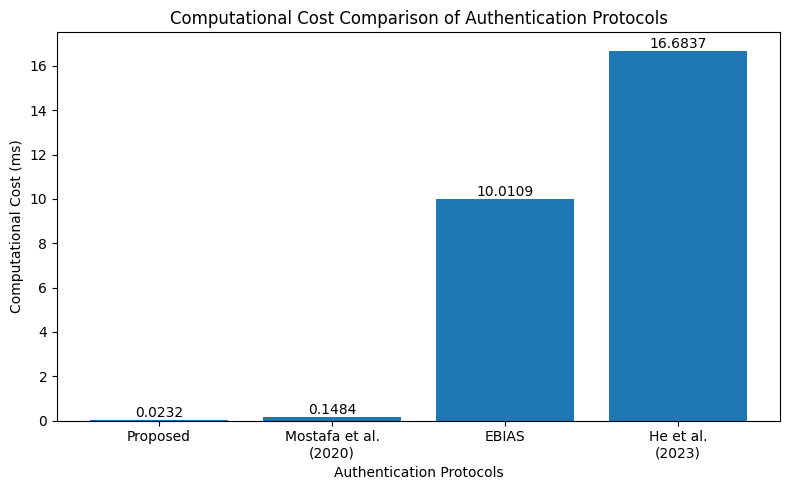

In [ ]:
import matplotlib.pyplot as plt

protocols = [
    "Proposed",
    "Mostafa et al.\n(2020)",
    "EBIAS",
    "He et al.\n(2023)"
]

costs = [
    0.023235,
    0.148403,
    10.010857,
    16.683743
]

plt.figure(figsize=(8,5))

bars = plt.bar(protocols, costs)

plt.ylabel("Computational Cost (ms)")
plt.xlabel("Authentication Protocols")
plt.title("Computational Cost Comparison of Authentication Protocols")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height,
        f"{height:.4f}",
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

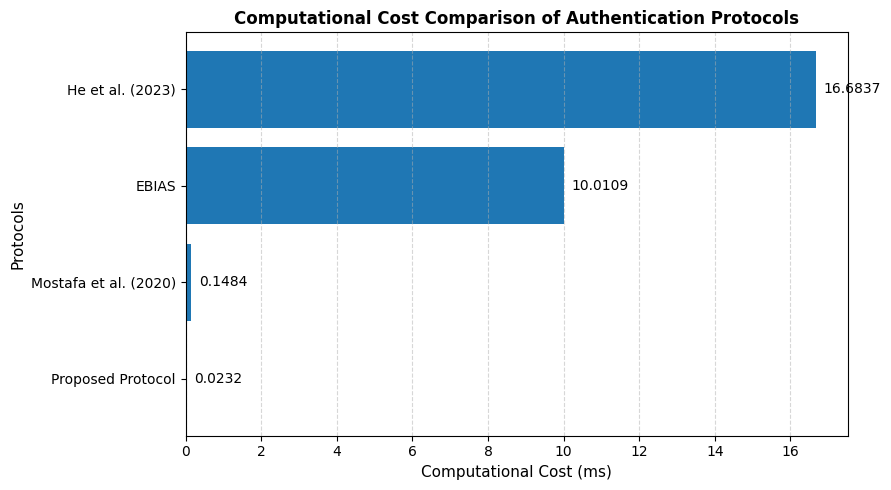

In [ ]:
import matplotlib.pyplot as plt

protocols = [
    "Proposed Protocol",
    "Mostafa et al. (2020)",
    "EBIAS",
    "He et al. (2023)"
]

costs = [
    0.023235,
    0.148403,
    10.010857,
    16.683743
]

plt.figure(figsize=(9,5))

bars = plt.barh(protocols, costs)

plt.xlabel("Computational Cost (ms)", fontsize=11)
plt.ylabel("Protocols", fontsize=11)
plt.title("Computational Cost Comparison of Authentication Protocols",
          fontsize=12,
          fontweight='bold')

for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.2,
             bar.get_y() + bar.get_height()/2,
             f"{width:.4f}",
             va='center')

plt.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

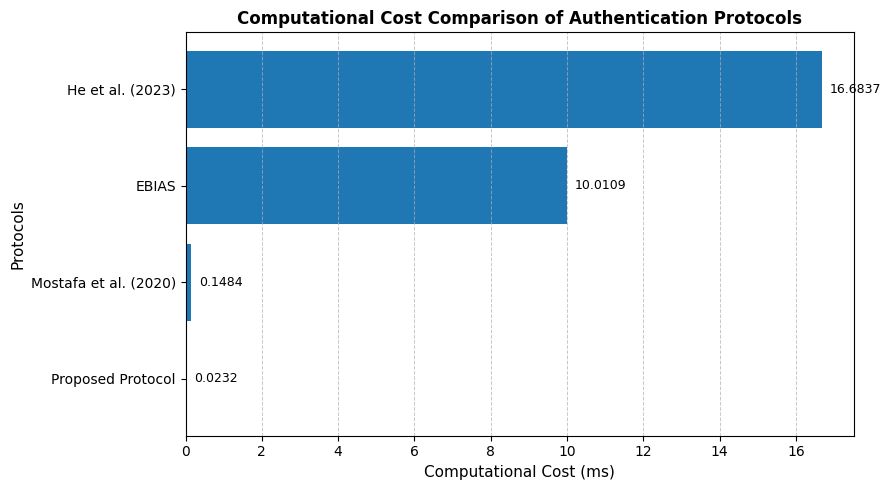

In [ ]:
import matplotlib.pyplot as plt

protocols = [
    "Proposed Protocol",
    "Mostafa et al. (2020)",
    "EBIAS",
    "He et al. (2023)"
]

costs = [
    0.023235,
    0.148403,
    10.010857,
    16.683743
]

plt.figure(figsize=(9,5))

bars = plt.barh(protocols, costs)

plt.xlabel("Computational Cost (ms)", fontsize=11)
plt.ylabel("Protocols", fontsize=11)

plt.title(
    "Computational Cost Comparison of Authentication Protocols",
    fontsize=12,
    fontweight='bold'
)

# Add grid lines
plt.grid(
    axis='x',
    linestyle='--',
    linewidth=0.7,
    alpha=0.7
)

# Add values on bars
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.2,
        bar.get_y() + bar.get_height()/2,
        f"{width:.4f}",
        va='center',
        fontsize=9
    )

plt.tight_layout()
plt.show()

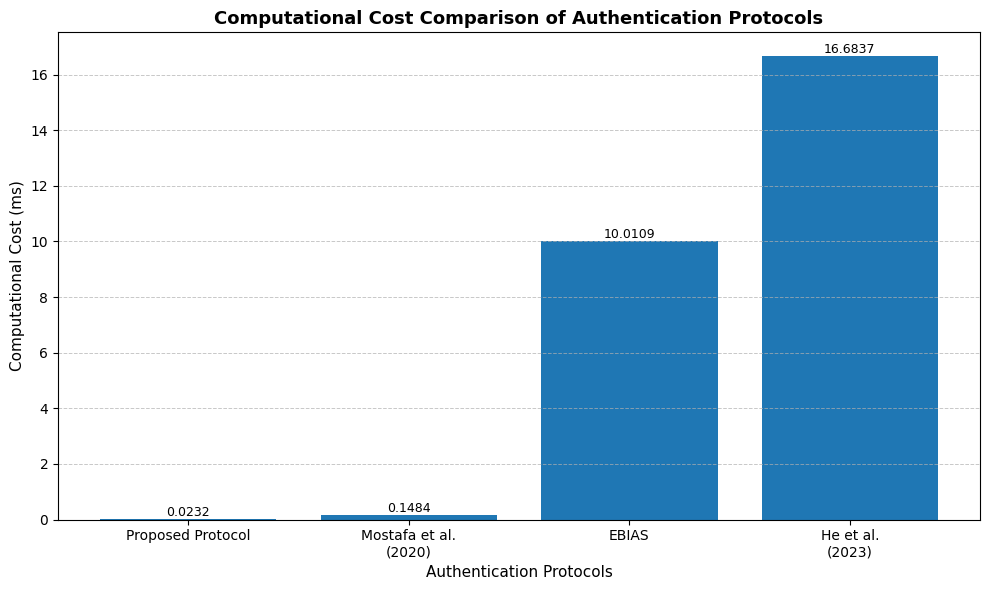

In [ ]:
import matplotlib.pyplot as plt

protocols = [
    "Proposed Protocol",
    "Mostafa et al.\n(2020)",
    "EBIAS",
    "He et al.\n(2023)"
]

costs = [
    0.023235,
    0.148403,
    10.010857,
    16.683743
]

plt.figure(figsize=(10, 6))

bars = plt.bar(protocols, costs)

plt.xlabel("Authentication Protocols", fontsize=11)
plt.ylabel("Computational Cost (ms)", fontsize=11)

plt.title(
    "Computational Cost Comparison of Authentication Protocols",
    fontsize=13,
    fontweight='bold'
)

# Grid lines
plt.grid(
    axis='y',
    linestyle='--',
    linewidth=0.7,
    alpha=0.7
)

# Values on top of bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height,
        f"{height:.4f}",
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.tight_layout()
plt.show()

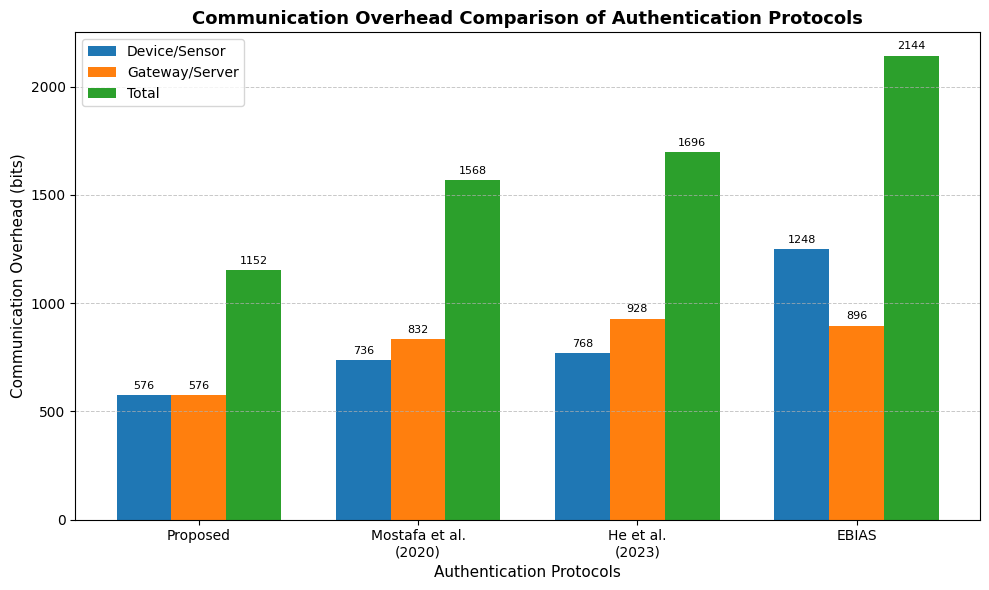

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

protocols = [
    "Proposed",
    "Mostafa et al.\n(2020)",
    "He et al.\n(2023)",
    "EBIAS"
]

device_bits = [576, 736, 768, 1248]
gateway_bits = [576, 832, 928, 896]
total_bits = [1152, 1568, 1696, 2144]

x = np.arange(len(protocols))
width = 0.25

plt.figure(figsize=(10,6))

bars1 = plt.bar(
    x - width,
    device_bits,
    width,
    label="Device/Sensor"
)

bars2 = plt.bar(
    x,
    gateway_bits,
    width,
    label="Gateway/Server"
)

bars3 = plt.bar(
    x + width,
    total_bits,
    width,
    label="Total"
)

plt.xlabel("Authentication Protocols", fontsize=11)
plt.ylabel("Communication Overhead (bits)", fontsize=11)

plt.title(
    "Communication Overhead Comparison of Authentication Protocols",
    fontsize=13,
    fontweight='bold'
)

plt.xticks(x, protocols)

plt.grid(
    axis='y',
    linestyle='--',
    linewidth=0.7,
    alpha=0.7
)

plt.legend()

# Add values on bars
for bars in [bars1, bars2, bars3]:
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width()/2,
            height + 20,
            f"{int(height)}",
            ha='center',
            va='bottom',
            fontsize=8
        )

plt.tight_layout()
plt.show()